# 06 - Stage 4 (Deep Learning): CNN + LSTM

Every earlier stage worked on 456 features that *we* chose. This model reads
the raw filtered 2-second window - 256 time steps x 19 channels - and learns
its own features:

- **1-D convolutions** slide short kernels along *time*, learning local
  waveform patterns (rhythms, transients) across all 19 channels at once.
- **Pooling** shortens the sequence from 256 to 16 steps, keeping the
  strongest responses.
- An **LSTM** reads those 16 steps in order and summarises how the patterns
  evolve across the 2 seconds.
- A small **dense head** turns that summary into P(ADHD).

If hand-made band powers were missing something, this is the stage that can
find it. If they were not, this model should land near Stage 1.

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, sys, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers as L, Sequential
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
tf.keras.utils.set_random_seed(42)

CACHE = "data/epochs.npz"
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## Step 1 - Load the raw epochs

**What this does.** Loads `Xr` - the filtered windows themselves, shape
(epochs, 256, 19) - plus labels and subject IDs. No feature matrix this time.

**Getting the shape right matters.** Keras reads the input as
`(batch, time steps, features)`. Here time steps = 256 samples and features =
19 channels, so convolutions run *along time*. Reshaping the other way round -
(19, 1) - would make the convolution run across electrodes in column order and
leave no time axis at all. That mistake is easy to make and silently produces a
model that trains, scores something, and means nothing.

In [2]:
if not os.path.exists(CACHE):
    raise FileNotFoundError("Run 01_Data_and_Preprocessing.ipynb first - it builds " + CACHE)
cache = np.load(CACHE, allow_pickle=True)
X_raw, y, groups = cache["Xr"], cache["y"].astype(int), cache["g"]

subj = pd.DataFrame({"ID": groups, "y": y}).groupby("ID").y.first()
print("raw epochs :", X_raw.shape, " <- (epochs, 256 time steps, 19 channels)")
print("subjects   :", len(subj), " (%d ADHD, %d Control)" % (subj.sum(), (1 - subj).sum()))

raw epochs : (16749, 256, 19)  <- (epochs, 256 time steps, 19 channels)
subjects   : 121  (61 ADHD, 60 Control)


## Step 2 - Build subject-grouped cross-validation folds

**What this does.** Splits the 121 subjects into 5 folds. Each fold holds out
about 24 *people*; all of their epochs go to the test side together.
`StratifiedGroupKFold` keeps the ADHD/Control balance similar across folds.

**Why 5 folds and not one split.** With only 121 subjects, which particular
people end up in the test set changes the score a lot. Five folds give five
estimates, and we report their mean and spread. A single split would hide that
spread entirely.

**Why there is an `assert`.** It is cheap insurance: if a future change ever
lets a subject leak across a split, the notebook stops here instead of quietly
reporting an inflated number.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, SEED = 5, 42
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
          .split(X_raw, y, groups))

for k, (tr, te) in enumerate(cv):
    assert not (set(groups[tr]) & set(groups[te])), "subject leaked across split!"
    print("fold %d: train %5d epochs / %2d subjects   test %4d epochs / %2d subjects"
          % (k, len(tr), len(set(groups[tr])), len(te), len(set(groups[te]))))
print("\nVerified: no subject appears on both sides of any fold.")

fold 0: train 13419 epochs / 97 subjects   test 3330 epochs / 24 subjects
fold 1: train 13412 epochs / 97 subjects   test 3337 epochs / 24 subjects
fold 2: train 13342 epochs / 96 subjects   test 3407 epochs / 25 subjects
fold 3: train 13413 epochs / 97 subjects   test 3336 epochs / 24 subjects
fold 4: train 13410 epochs / 97 subjects   test 3339 epochs / 24 subjects

Verified: no subject appears on both sides of any fold.


## Step 3 - Define how a model is scored

**What this does.** Two helpers used by every model notebook.

- `subject_scores` turns epoch-level predictions into one decision per person
  by **averaging that person's epoch probabilities**, then scores those
  decisions. This is the number that matters: diagnosis happens per person, not
  per 2-second window.
- `save_result` writes the 5-fold summary (and each fold's score) to
  `results.csv` / `results_folds.csv`, which notebook `07` reads.

**Why ROC-AUC alongside accuracy.** Accuracy depends on where the 0.5 cut-off
sits; ROC-AUC measures how well the model *ranks* ADHD subjects above controls,
regardless of the cut-off. Both are reported. The standard deviation is the
sample SD across the 5 folds.

In [4]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve

def subject_scores(g_te, y_te, p):
    """Average epoch probabilities per subject, then score the per-subject decision."""
    s = (pd.DataFrame({"ID": g_te, "y": y_te, "p": p})
         .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    pred = (s.p > 0.5).astype(int)
    return roc_auc_score(s.y, s.p), accuracy_score(s.y, pred), f1_score(s.y, pred)

def save_result(model, stage, res, path="results.csv"):
    """Upsert one model's summary row; per-fold rows go to results_folds.csv."""
    row = dict(model=model, stage=stage, n_folds=len(res))
    for c in ("epoch_auc", "subject_auc", "subject_acc", "subject_f1"):
        row[c], row[c + "_sd"] = res[c].mean(), res[c].std()
    for p, new in ((path, pd.DataFrame([row])),
                   (path.replace(".csv", "_folds.csv"), res.assign(model=model, stage=stage))):
        try:
            old = pd.read_csv(p); old = old[old.model != model]
            new = pd.concat([old, new], ignore_index=True)
        except FileNotFoundError:
            pass
        new.sort_values(["stage", "model"]).to_csv(p, index=False)
    print("saved %s -> %s" % (model, path))

print("helpers defined")

helpers defined


## Step 4 - Define the network

**Layer by layer.**

| Layer | Output | Role |
|---|---|---|
| Conv1D(64, k=7) + BatchNorm + MaxPool(4) + Dropout | (64, 64) | learn 64 short waveform detectors; pool 256 -> 64 steps |
| Conv1D(64, k=5) + BatchNorm + MaxPool(4) + Dropout | (16, 64) | combine them into longer patterns; pool 64 -> 16 steps |
| LSTM(64) | (64,) | read the 16 steps in order, keep a summary |
| Dense(32) + Dropout, Dense(1, sigmoid) | P(ADHD) | classifier head |

**Why pool before the LSTM.** An LSTM over 256 steps is slow and hard to train
on CPU; over 16 pooled steps it is cheap and still sees the whole 2 seconds.
**Dropout 0.3** throughout and **BatchNorm** after each convolution are the
regularisation - with ~97 training subjects per fold, overfitting is the main
risk.

In [5]:
def build_cnn_lstm(shape):
    return Sequential([
        L.Input(shape=shape),
        L.Conv1D(64, 7, padding="same", activation="relu"), L.BatchNormalization(), L.MaxPooling1D(4), L.Dropout(.3),
        L.Conv1D(64, 5, padding="same", activation="relu"), L.BatchNormalization(), L.MaxPooling1D(4), L.Dropout(.3),
        L.LSTM(64), L.Dropout(.3),
        L.Dense(32, activation="relu"), L.Dropout(.3),
        L.Dense(1, activation="sigmoid"),
    ], name="cnn_lstm")

build_cnn_lstm(X_raw.shape[1:]).summary()

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 256, 64)        │         8,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,769 (253.00 KB)

 Trainable params: 64,513 (252.00 KB)

 Non-trainable params: 256 (1.00 KB)

## Step 5 - The training procedure for one fold

**What this does**, in order, for a given train/test fold:

1. **Normalise per channel** using the *training* epochs' mean and standard
   deviation. Each electrode has its own amplitude scale; one global mean/std
   would blur them together.
2. **Carve an inner validation set** from the training subjects (again grouped
   by subject) for early stopping. The test fold is never used to decide when
   to stop - doing so would let it pick the best epoch and bias the score up.
3. **Class weights** from the training fold, for the same 56/44 reason as
   before.
4. **Early stopping** on validation AUC with patience 8, restoring the best
   weights. Up to 40 epochs, batch size 128, Adam at 1e-3.

Returns the test-fold probabilities and the training history.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

def fit_predict(tr, te, epochs=40, batch=128):
    tf.keras.utils.set_random_seed(42)
    mu = X_raw[tr].mean(axis=(0, 1), keepdims=True)
    sd = X_raw[tr].std(axis=(0, 1), keepdims=True) + 1e-8
    Xtr, Xte = (X_raw[tr] - mu) / sd, (X_raw[te] - mu) / sd

    itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42).split(Xtr, y[tr], groups[tr]))

    m = build_cnn_lstm(X_raw.shape[1:])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])
    n = len(tr); cw = {0: n / (2 * (y[tr] == 0).sum()), 1: n / (2 * (y[tr] == 1).sum())}
    hist = m.fit(Xtr[itr], y[tr][itr], validation_data=(Xtr[iva], y[tr][iva]),
                 epochs=epochs, batch_size=batch, class_weight=cw, verbose=0,
                 callbacks=[EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)])
    return m.predict(Xte, batch_size=512, verbose=0).ravel(), hist.history

print("fit_predict defined")

fit_predict defined


## Step 6 - Train and evaluate across the 5 folds

**What this does.** The same loop as every other notebook, now calling the
Keras procedure. Expect a few minutes per fold on CPU; the time per fold is
printed. The history of fold 0 is kept for the training curves below.

In [7]:
rows, oof_p, oof_y, oof_g, histories = [], [], [], [], []
for k, (tr, te) in enumerate(cv):
    t0 = time.time()
    p, h = fit_predict(tr, te)
    histories.append(h)
    ep_auc = roc_auc_score(y[te], p)
    s_auc, s_acc, s_f1 = subject_scores(groups[te], y[te], p)
    rows.append(dict(fold=k, epoch_auc=ep_auc, subject_auc=s_auc, subject_acc=s_acc, subject_f1=s_f1,
                     epochs_trained=len(h["loss"])))
    oof_p.append(p); oof_y.append(y[te]); oof_g.append(groups[te])
    print("fold %d  epoch-AUC %.3f | subject-AUC %.3f  subject-acc %.3f | %d training epochs, %.0f s"
          % (k, ep_auc, s_auc, s_acc, len(h["loss"]), time.time() - t0))

res = pd.DataFrame(rows)
oof_p, oof_y, oof_g = map(np.concatenate, (oof_p, oof_y, oof_g))
print("\nCNN + LSTM  -  5-fold results")
for c in ["epoch_auc", "subject_auc", "subject_acc", "subject_f1"]:
    print("  %-12s %.3f +- %.3f" % (c, res[c].mean(), res[c].std()))
save_result("CNN-LSTM", "4 - Deep Learning", res)

fold 0  epoch-AUC 0.887 | subject-AUC 0.840  subject-acc 0.792 | 30 training epochs, 247 s


fold 1  epoch-AUC 0.798 | subject-AUC 0.826  subject-acc 0.750 | 19 training epochs, 68 s


fold 2  epoch-AUC 0.903 | subject-AUC 0.962  subject-acc 0.880 | 21 training epochs, 100 s


fold 3  epoch-AUC 0.659 | subject-AUC 0.708  subject-acc 0.583 | 10 training epochs, 77 s


fold 4  epoch-AUC 0.925 | subject-AUC 0.958  subject-acc 0.833 | 23 training epochs, 188 s

CNN + LSTM  -  5-fold results
  epoch_auc    0.834 +- 0.109
  subject_auc  0.859 +- 0.105
  subject_acc  0.768 +- 0.114
  subject_f1   0.791 +- 0.091
saved CNN-LSTM -> results.csv


## Step 7 - Training curves

**What this does.** Plots loss and AUC per training epoch for every fold,
training set versus inner validation set.

**How to read them.** Training loss should fall steadily. Validation AUC rising
then flattening or dipping is the point early stopping is looking for; the
weights from the best validation epoch are the ones that were tested. A wide
and growing gap between the two curves is overfitting - expected to some
degree with this little independent data.

**What these curves show on this data.** Training AUC reaches about 1.0 within five epochs while validation AUC plateaus between roughly 0.75 and 0.88 and validation *loss rises* - the network memorises its training epochs almost immediately and then grows over-confident. Generalisation here rests entirely on early stopping and dropout. That is what ~97 training subjects buys: far more model capacity than independent examples.

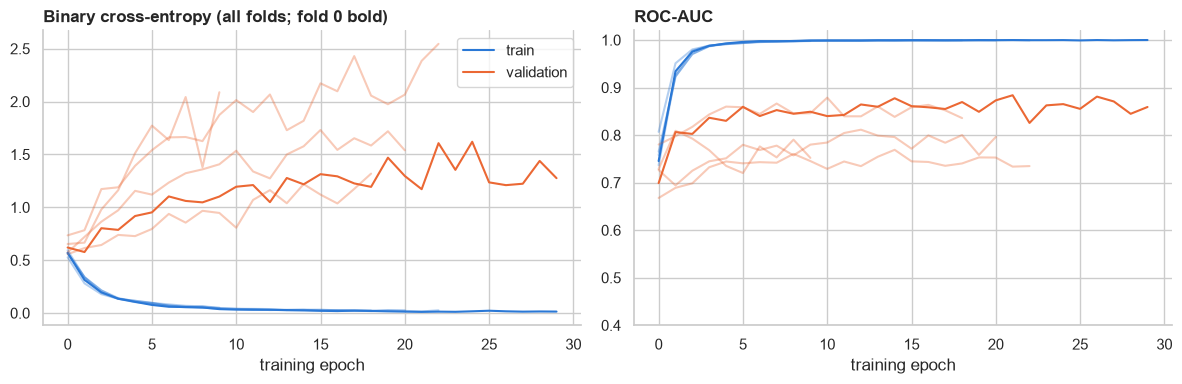

training epochs used per fold: [30, 19, 21, 10, 23]  (early stopping, patience 8)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, h in enumerate(histories):
    a = 0.35 + 0.65 * (k == 0)
    ax[0].plot(h["loss"], color=BLUE, alpha=a, lw=1.5, label="train" if k == 0 else None)
    ax[0].plot(h["val_loss"], color="#eb6834", alpha=a, lw=1.5, label="validation" if k == 0 else None)
    ax[1].plot(h["auc"], color=BLUE, alpha=a, lw=1.5)
    ax[1].plot(h["val_auc"], color="#eb6834", alpha=a, lw=1.5)
ax[0].set_title("Binary cross-entropy (all folds; fold 0 bold)", weight="bold", loc="left"); ax[0].set_xlabel("training epoch"); ax[0].legend()
ax[1].set_title("ROC-AUC", weight="bold", loc="left"); ax[1].set_xlabel("training epoch"); ax[1].set_ylim(.4, 1.02)
for a in ax:
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()
print("training epochs used per fold:", res.epochs_trained.tolist(), " (early stopping, patience 8)")

## Step 8 - One decision per subject

**What this does.** Pools the out-of-fold predictions - every subject was in a
test fold exactly once - and makes the final per-person call by averaging that
person's epoch probabilities.

**Why the pooled numbers differ slightly from the fold means.** The fold means
average five scores each computed on about 24 people; the pooled score is
computed once on all 121. Both are legitimate; the fold mean comes with a
spread, which is why the tables quote it.

In [9]:
subject_pred = (pd.DataFrame({"ID": oof_g, "y_true": oof_y, "p": oof_p})
                .groupby("ID").agg(y_true=("y_true", "first"), p_adhd=("p", "mean")))
subject_pred["pred"] = (subject_pred.p_adhd > 0.5).astype(int)
subject_pred["correct"] = subject_pred.pred == subject_pred.y_true

print("Pooled subject-level performance (n = %d)" % len(subject_pred))
print("  accuracy : %.3f" % accuracy_score(subject_pred.y_true, subject_pred.pred))
print("  ROC-AUC  : %.3f" % roc_auc_score(subject_pred.y_true, subject_pred.p_adhd))
print("  F1       : %.3f" % f1_score(subject_pred.y_true, subject_pred.pred))

wrong = subject_pred[~subject_pred.correct].assign(margin=lambda d: (d.p_adhd - .5).abs())
print("\n%d of %d subjects misclassified. Most confident mistakes:" % (len(wrong), len(subject_pred)))
display(wrong.sort_values("margin", ascending=False).head(5).round(3))

Pooled subject-level performance (n = 121)
  accuracy : 0.769
  ROC-AUC  : 0.887
  F1       : 0.788

28 of 121 subjects misclassified. Most confident mistakes:


,y_true,p_adhd,pred,correct,margin
ID,,,,,
v51p,0,0.999,1,False,0.499
v6p,1,0.049,0,False,0.451
v44p,0,0.922,1,False,0.422
v59p,0,0.892,1,False,0.392
v60p,0,0.881,1,False,0.381


## Step 9 - Confusion matrix and ROC curve

**How to read them.** Left column: every 2-second epoch scored on its own.
Right column: one decision per subject. The subject-level matrix has 121 cells
in total - the top-right cell is controls flagged as ADHD, the bottom-left is
ADHD subjects missed. The ROC curve plots sensitivity against false-alarm rate
at every possible cut-off; the area under it is the ROC-AUC quoted above.

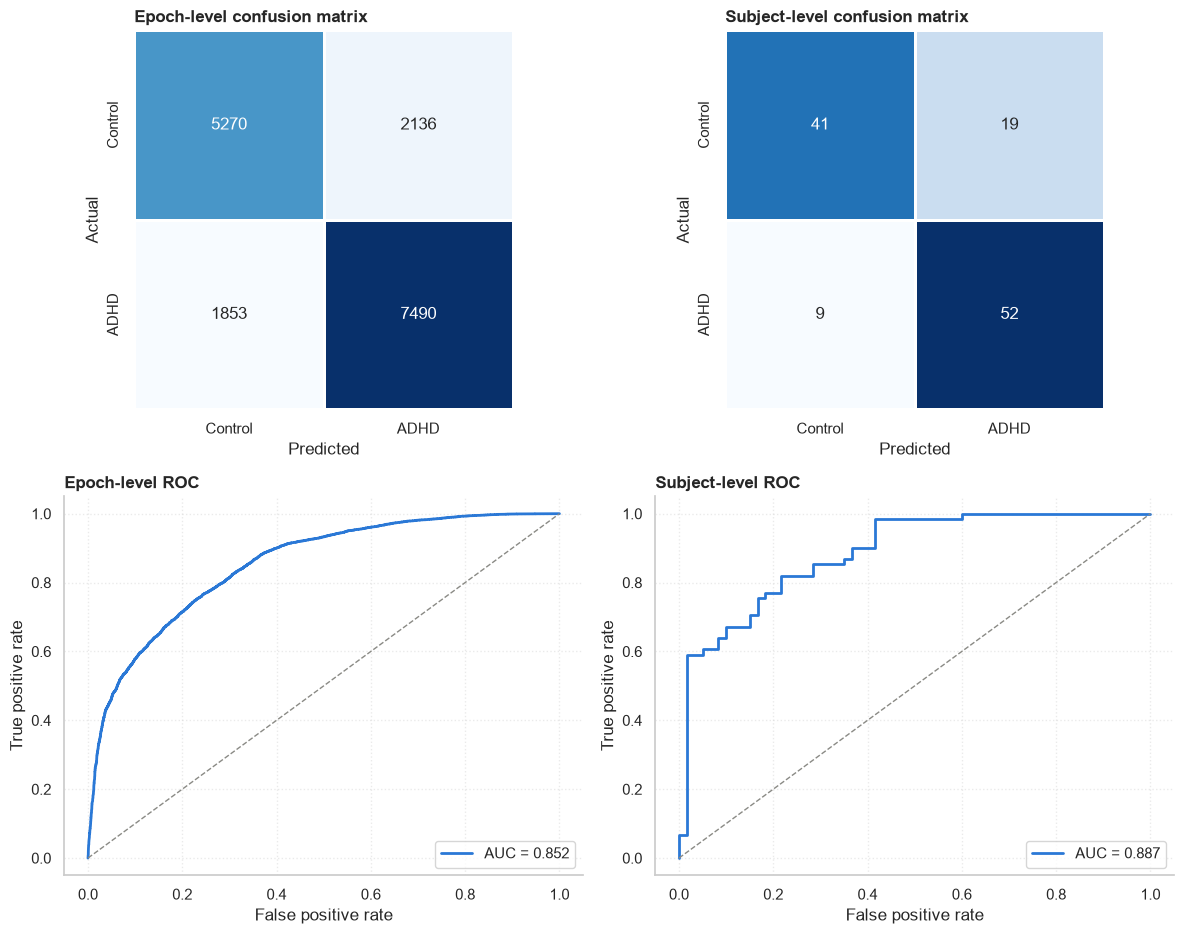

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
levels = [(oof_y, oof_p, "Epoch"),
          (subject_pred.y_true.values, subject_pred.p_adhd.values, "Subject")]

for col, (yy, pp, lvl) in enumerate(levels):
    cm = confusion_matrix(yy, (pp > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1, linecolor="white", ax=ax[0, col],
                xticklabels=["Control", "ADHD"], yticklabels=["Control", "ADHD"])
    ax[0, col].set_title("%s-level confusion matrix" % lvl, weight="bold", loc="left")
    ax[0, col].set_xlabel("Predicted"); ax[0, col].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(yy, pp)
    ax[1, col].plot(fpr, tpr, lw=2, color=BLUE, label="AUC = %.3f" % roc_auc_score(yy, pp))
    ax[1, col].plot([0, 1], [0, 1], "--", color="#8a8a85", lw=1)
    ax[1, col].set_title("%s-level ROC" % lvl, weight="bold", loc="left")
    ax[1, col].set_xlabel("False positive rate"); ax[1, col].set_ylabel("True positive rate")
    ax[1, col].legend(loc="lower right"); ax[1, col].grid(alpha=.4, ls=":")
    for sp in ("top", "right"): ax[1, col].spines[sp].set_visible(False)

plt.tight_layout(); plt.show()

## Step 10 - How much the score moves from fold to fold

**Why this plot is here.** It is the honest picture of uncertainty. Each pair
of bars is one fold - one particular set of ~24 test subjects. The gap between
the best and worst fold is what a single train/test split would have hidden:
the same model, the same code, and a score that depends on which people were
held out.

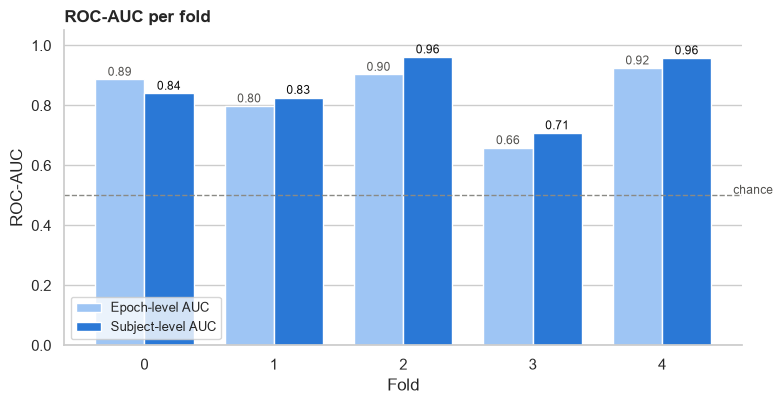

subject-AUC: best fold 0.962, worst fold 0.708, spread 0.253


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38
ax.bar(res.fold - w/2, res.epoch_auc, w, color="#9ec5f4", label="Epoch-level AUC")
ax.bar(res.fold + w/2, res.subject_auc, w, color=BLUE, label="Subject-level AUC")
for f, e, s in zip(res.fold, res.epoch_auc, res.subject_auc):
    ax.text(f - w/2, e + .012, "%.2f" % e, ha="center", fontsize=8.5, color=MUTED)
    ax.text(f + w/2, s + .012, "%.2f" % s, ha="center", fontsize=8.5, color=INK)
ax.axhline(.5, ls="--", lw=1, color="#8a8a85"); ax.text(4.55, .505, "chance", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.05); ax.set_xticks(res.fold); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold", weight="bold", loc="left")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("subject-AUC: best fold %.3f, worst fold %.3f, spread %.3f"
      % (res.subject_auc.max(), res.subject_auc.min(), res.subject_auc.max() - res.subject_auc.min()))

## How to report this

- Quote the **subject-level** figures **with their +- SD**. With ~24 subjects
  per test fold, one person is worth about 4 percentage points of accuracy, so
  the spread is part of the result.
- Compare against the other stages in `07_Model_Comparison.ipynb`. A model
  whose mean is higher by less than one standard deviation has **not** been
  shown to be better on this data.
- **On this model specifically:** if its interval overlaps Stage 1's within one
  standard deviation, the data has not shown that deep learning helped - with
  121 subjects that is a real possibility and a legitimate finding. Look at the
  per-fold comparison in `07`: beating the baseline on most folds is a stronger
  sign than a higher mean.